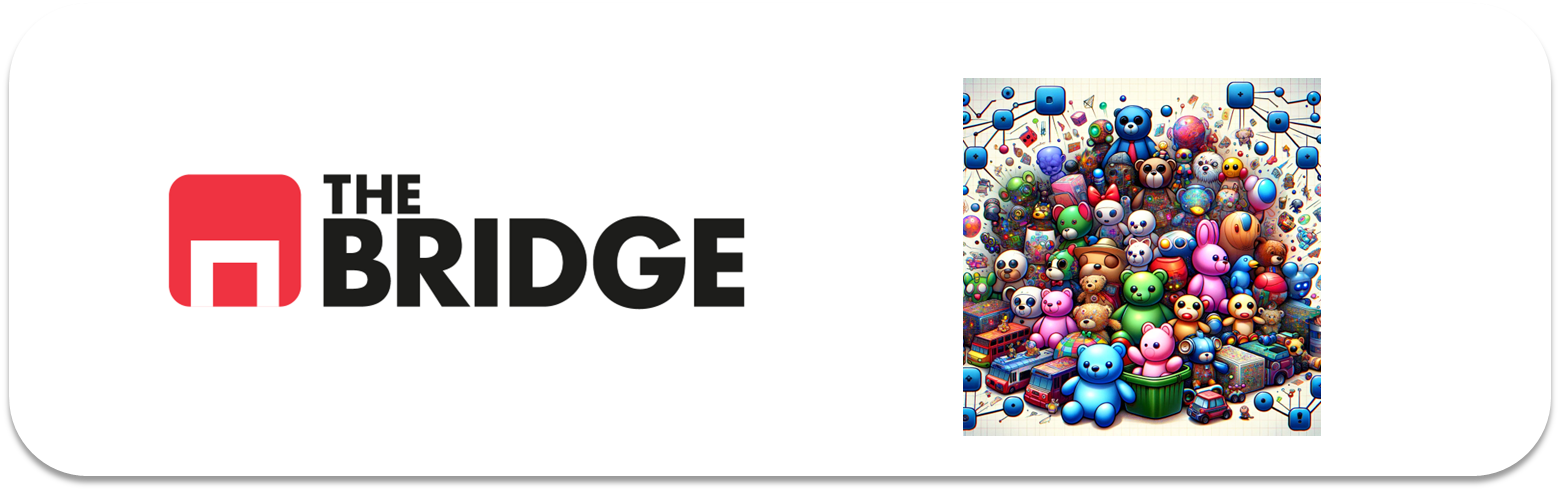

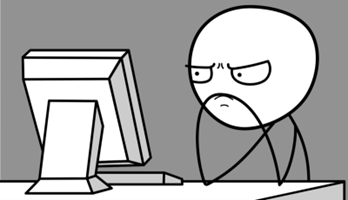

Para ejercitarte y afianzar lo aprendido sobre **Clustering Jerárquico**, completa los siguientes ejercicios. Recuerda que necesitarás los datos del directorio `data` de la unidad (`../data`).

Ya tienes las soluciones: intenta no mirarlas de primeras, pero no dejes de hacerlo cuando hayas terminado, por si te pudieran aportar.

### Descripción del "Problema"

Existen disponibles datos de encuestas y cuestionarios a 26 instituciones. Estas instituciones han sido evaluadas bajo distintos criterios de desempeño: profesorado (`Teaching`), coste (`Fees`), salidas laborales (`Placements`), prácticas (`Internship`) e infraestructuras (`Infrastructure`). Cada criterio va del 1 al 5: en todos ellos 5 es la mejor valoración, salvo en `Fees`, donde 5 indica el coste más alto (las instituciones más caras).

El objetivo principal será segmentar las instituciones en grupos basándonos en los criterios antes mencionados, y luego generar descripciones y recomendaciones a seguir con respecto a cada uno de los grupos identificados. Las recomendaciones pueden ser para distintos clientes.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import bootcampviztools as bt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import seaborn as sns


from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Ignoramos los avisos
import warnings
warnings.filterwarnings('ignore')

### Ejercicio 1

Carga los datos ("Engg_College_Data") y haz una primera inspección "rápida".

In [2]:
df_eng_college = pd.read_csv('../data/Engg_College_Data.csv')
df_eng_college.head()

,SR_NO,Engg_College,Teaching,Fees,Placements,Internship,Infrastructure
0,1,A,5,2,5,5,3
1,2,B,4,2,5,5,3
2,3,C,4,5,5,4,5
3,4,D,5,4,5,4,4
4,5,E,2,5,2,2,5


In [3]:
df_eng_college.describe(include='all')

,SR_NO,Engg_College,Teaching,Fees,Placements,Internship,Infrastructure
count,26.000000,26,26.000000,26.000000,26.000000,26.000000,26.000000
unique,NaN,26,NaN,NaN,NaN,NaN,NaN
top,NaN,A,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,NaN,NaN,NaN,NaN,NaN
mean,13.500000,NaN,2.807692,3.576923,2.884615,2.769231,3.384615
std,7.648529,NaN,1.132051,1.331858,1.531716,1.242826,1.298520
min,1.000000,NaN,1.000000,1.000000,1.000000,1.000000,1.000000
25%,7.250000,NaN,2.000000,2.250000,1.250000,2.000000,3.000000
50%,13.500000,NaN,3.000000,4.000000,3.000000,2.000000,3.000000
75%,19.750000,NaN,3.000000,5.000000,4.000000,4.000000,4.750000


In [4]:
df_eng_college.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   SR_NO           26 non-null     int64 
 1   Engg_College    26 non-null     object
 2   Teaching        26 non-null     int64 
 3   Fees            26 non-null     int64 
 4   Placements      26 non-null     int64 
 5   Internship      26 non-null     int64 
 6   Infrastructure  26 non-null     int64 
dtypes: int64(6), object(1)
memory usage: 1.6+ KB


*Tanto "SR_NO" como "Engg_College" tienen valores únicos; nos quedamos con "Engg_College".*

### Ejercicio 2

Crea un train_set con una única variable de tipo índice (que nos servirá para identificar a las instituciones en cada clúster).

*Las dos columnas con valores únicos para todas las instancias son SR_NO y Engg_College; nos quedamos con esta última.*

In [5]:
train_set = df_eng_college.drop(["SR_NO"], axis = 1)

### Ejercicio 3

Determina el tipo de cada variable, haciendo un univariante de las mismas.

In [6]:
features = train_set.columns.to_list()
features.remove("Engg_College")

*Considerándolas todas como numéricas continuas:*

(5, 2)


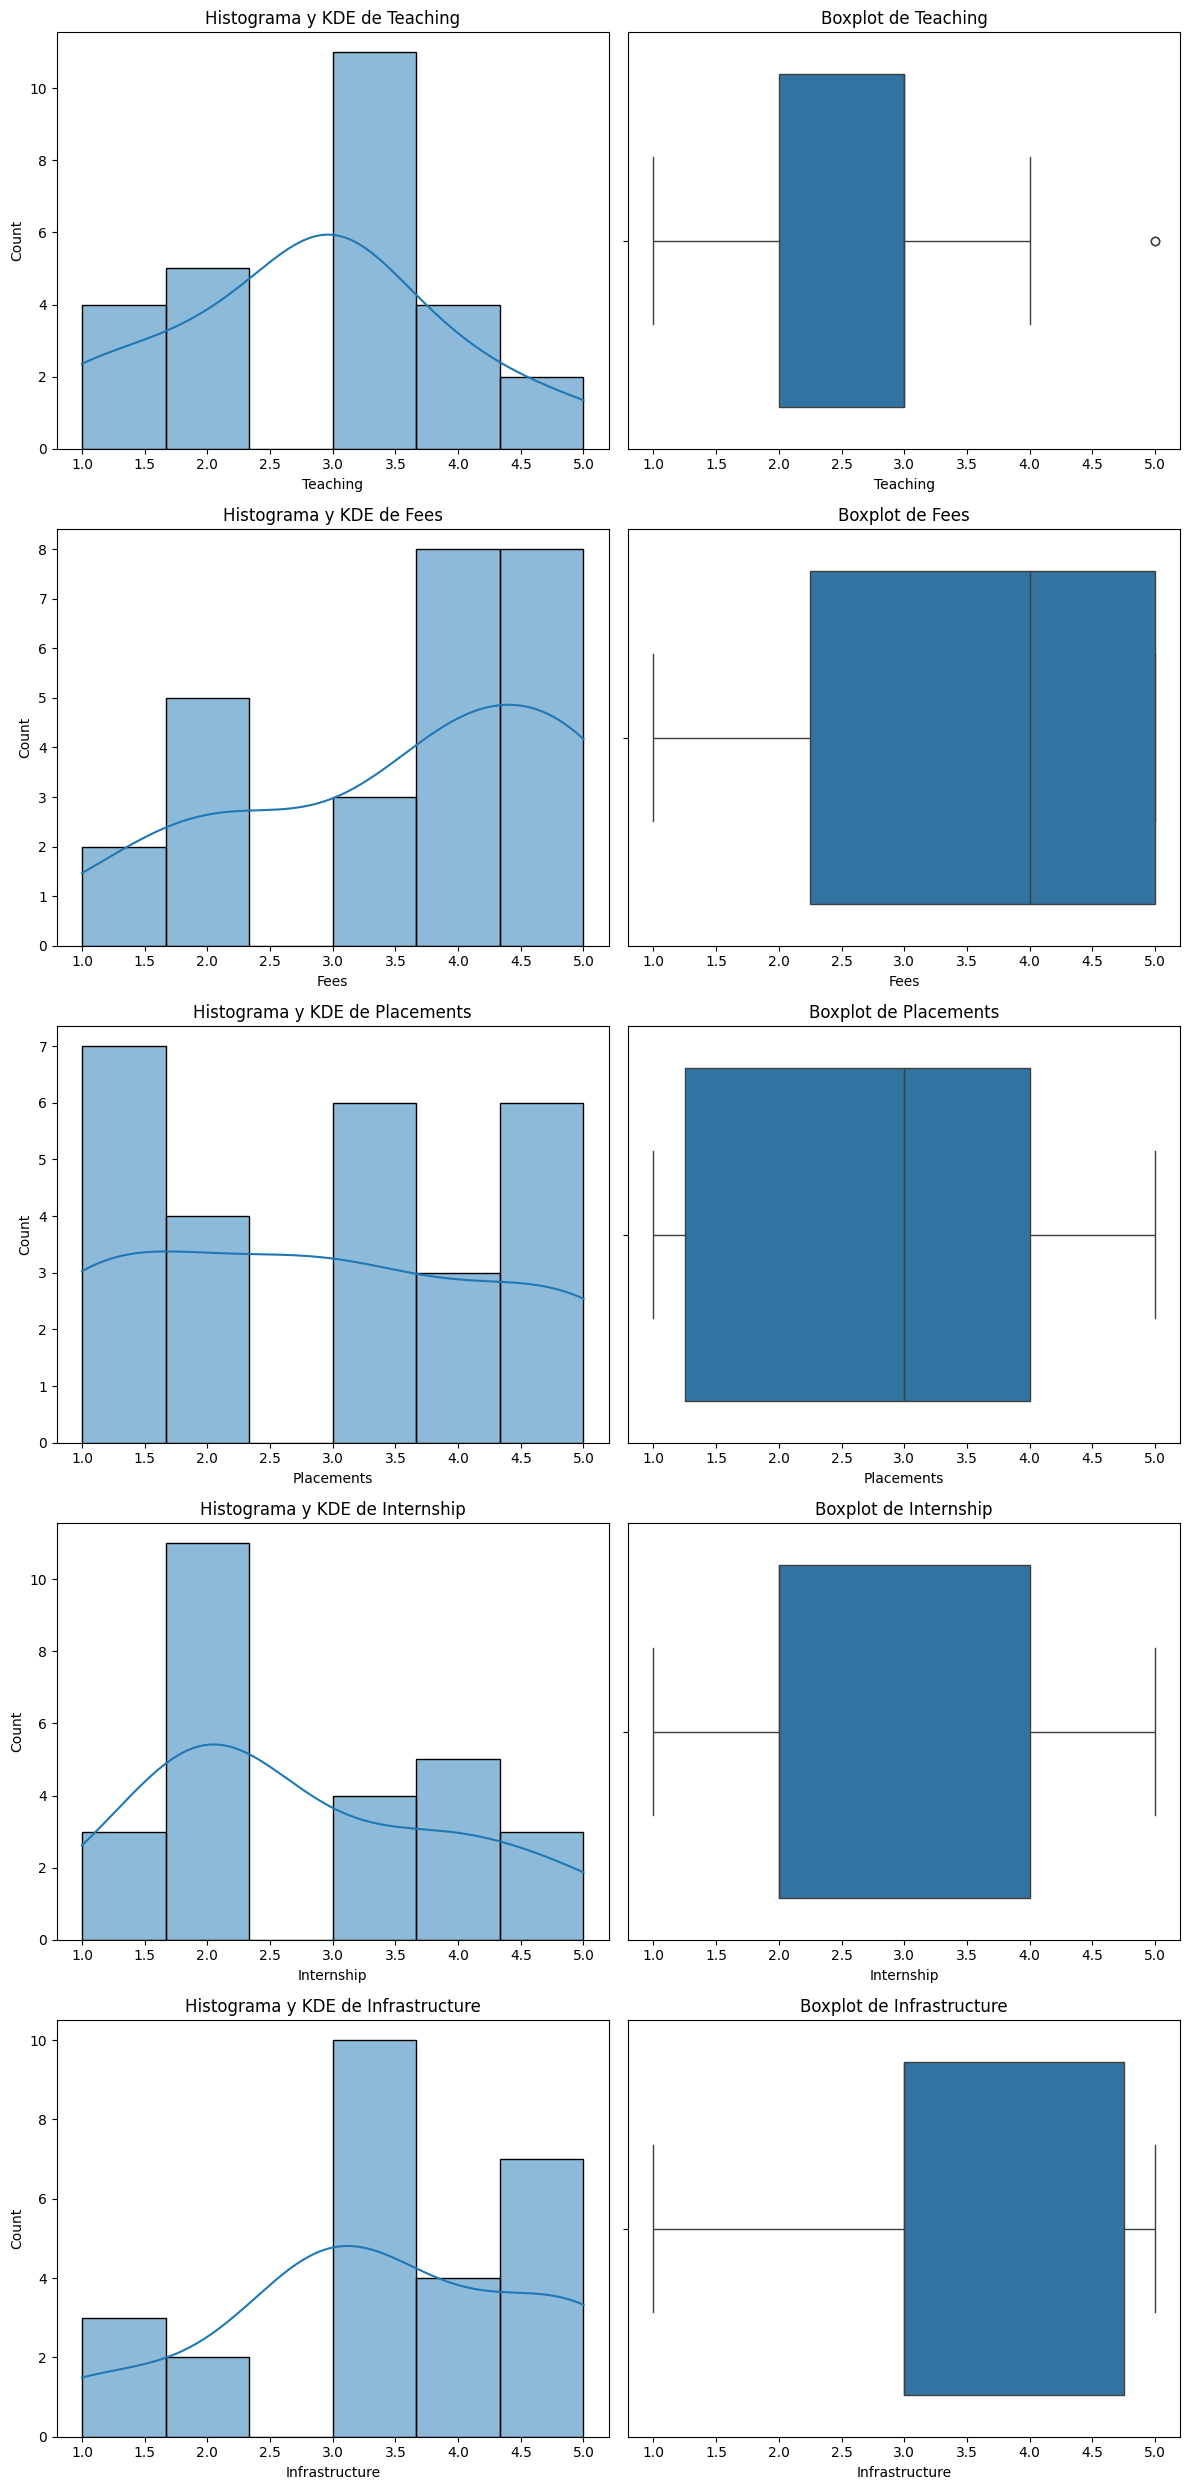

In [7]:
bt.plot_combined_graphs(train_set, features)

*Nos podíamos haber ahorrado el gráfico anterior acudiendo a la definición que nos dieron al principio y haciendo un value_counts:*

In [8]:
for col in features:
    print(f"{col}:")
    print(train_set[col].value_counts())
    print("****")

Teaching:
Teaching
3    11
2     5
4     4
1     4
5     2
Name: count, dtype: int64
****
Fees:
Fees
5    8
4    8
2    5
3    3
1    2
Name: count, dtype: int64
****
Placements:
Placements
1    7
5    6
3    6
2    4
4    3
Name: count, dtype: int64
****
Internship:
Internship
2    11
4     5
3     4
5     3
1     3
Name: count, dtype: int64
****
Infrastructure:
Infrastructure
3    10
5     7
4     4
1     3
2     2
Name: count, dtype: int64
****


*Como ya sabíamos, son variables numéricas discretas que podemos considerar categóricas ordinales.*

*Gráficamente:*

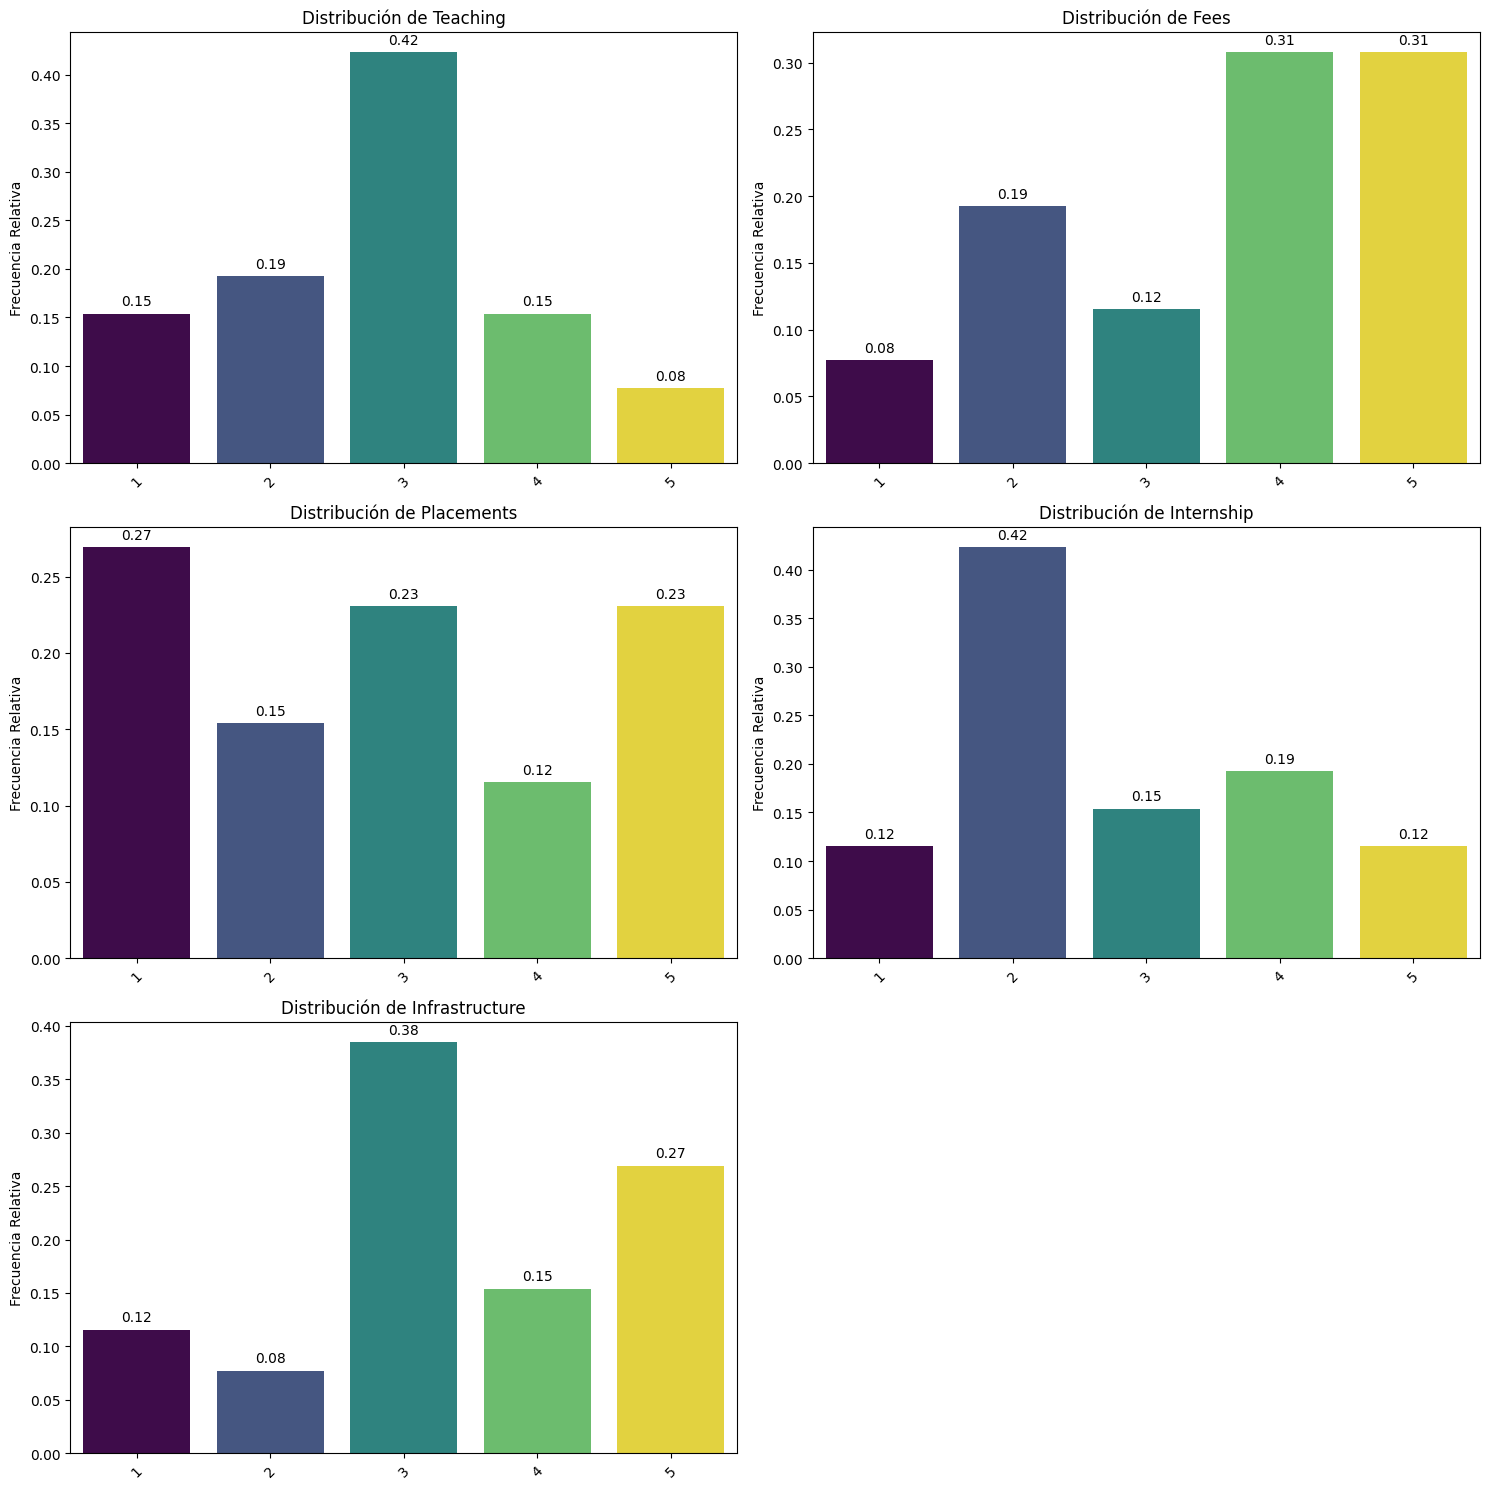

In [9]:
bt.pinta_distribucion_categoricas(train_set, features, mostrar_valores= True, relativa= True)

### Ejercicio 4

Es hora de hacer el miniEDA. Fíjate en que en este caso no tenemos variables numéricas continuas que nos permitan ver claramente una clusterización con scatter plots. Compruébalo haciendo un pairplot del dataset.

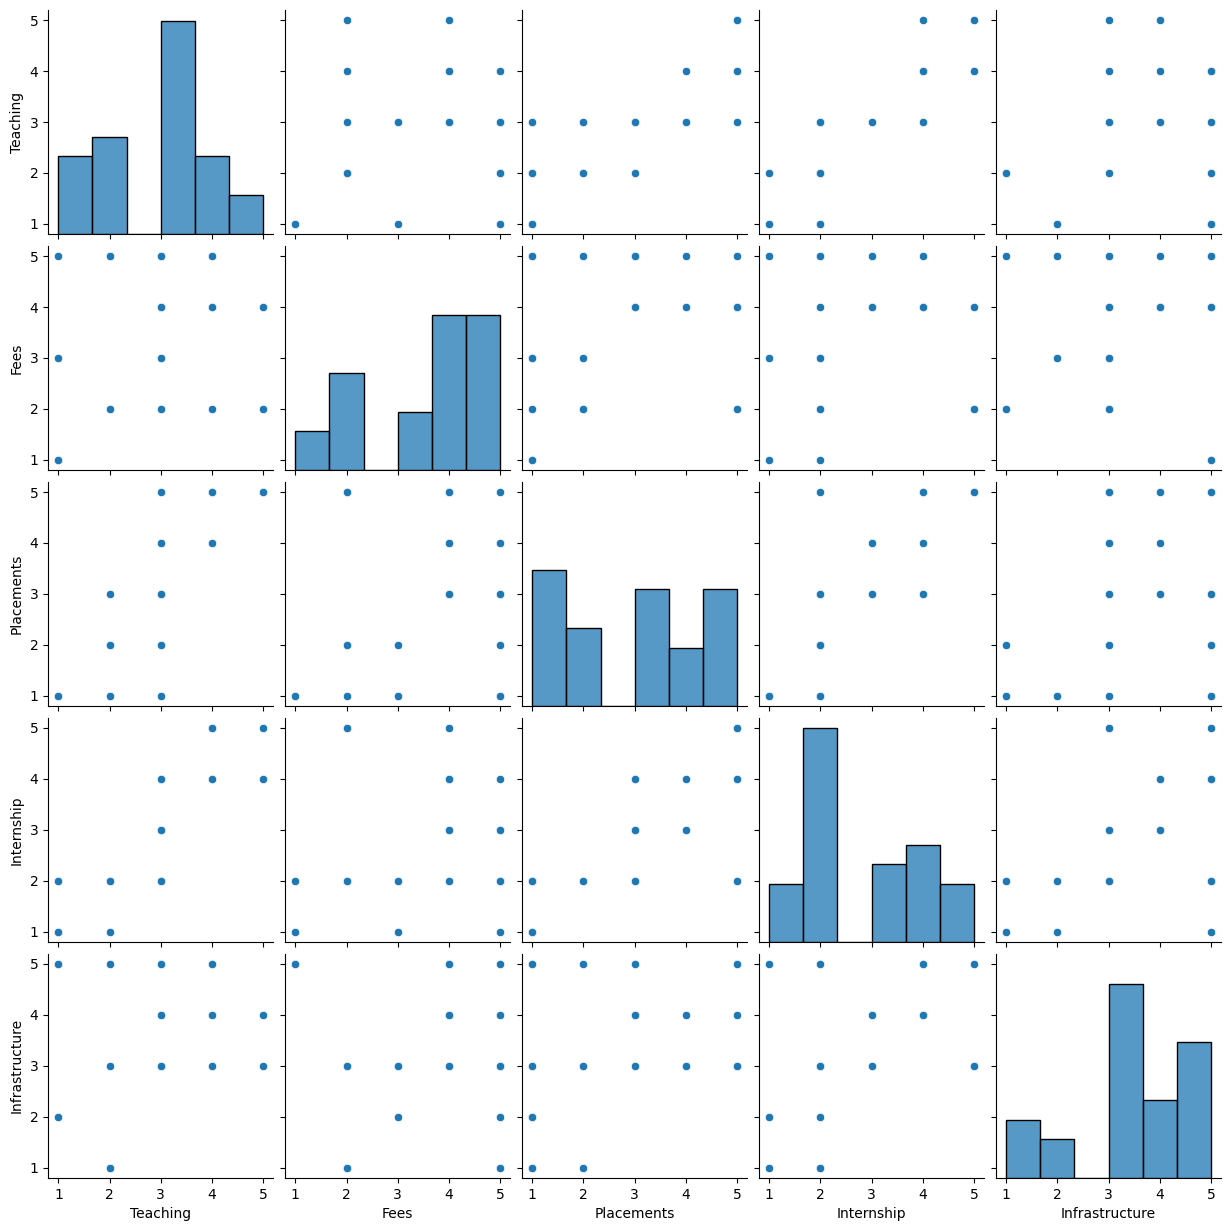

In [10]:
sns.pairplot(train_set[features])

### Ejercicio 5

Podríamos intentar cualquier tipo de clusterización, pero vamos a emplear una clusterización jerárquica porque, sea cual sea la agrupación, sí que nos interesa establecer una jerarquía o una relación de distancia entre las diferentes instituciones (es algo que nos piden desde el cliente, o sea, "Negocio").

Elegido el tipo de clustering, tenemos que determinar los hiperparámetros. En este caso, el número de clústeres. Para ello nos vamos a apoyar en el dendrograma. Construye el dendrograma utilizando "average" como el método de ligado o linkage.



NOTA: No lo hemos hecho ni dicho, pero nos quedaremos con todas las variables como features y, como están en la misma escala, no hay que procesarlas.

In [11]:
link_method = linkage(train_set[features], method = 'average')

In [12]:
labelList = np.array(train_set["Engg_College"])
labelList

array(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M',
       'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z'],
      dtype=object)

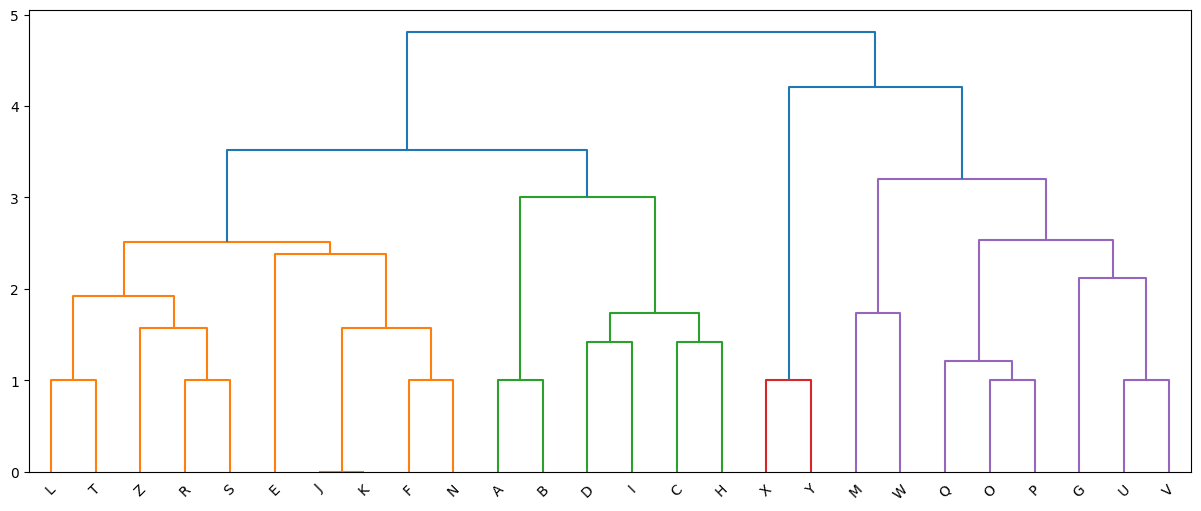

In [13]:
plt.figure(figsize =(15,6))
dend = dendrogram(link_method, labels= labelList)


### Ejercicio 6

Utilizando el método del máximo salto horizontal o método del máximo gap, ¿dónde colocarías la recta de corte? Vuelve a dibujar el dendrograma superponiendo esa línea. Decide el número de clústeres.

*El método del máximo gap busca el mayor tramo vertical del dendrograma que no corta ninguna unión horizontal (sin contar el que simplifica el clustering a 2 grupos). Veamos las alturas (distancias) de las últimas uniones:*

In [14]:
link_method[::-1][:6, 2] # Distancias de las 6 últimas uniones, de mayor a menor

array([4.8145543 , 4.20938008, 3.52454341, 3.20494584, 3.00156092,
       2.53330089])

*El mayor salto está entre 3,52 y 4,21, así que, siguiendo estrictamente el método, cortaríamos ahí y obtendríamos 3 clústeres. Sin embargo, fíjate en los colores del dendrograma: scipy colorea por defecto los clústeres que quedan por debajo del 70% de la altura máxima (0,7 × 4,81 ≈ 3,37), y con ese criterio salen 4 grupos (puede que el juego de colores en tu ordenador sea diferente). Como el salto entre 3,20 y 3,52 también es apreciable y con 4 clústeres aislamos un grupo muy particular (lo veremos enseguida), nos quedamos con 4.*

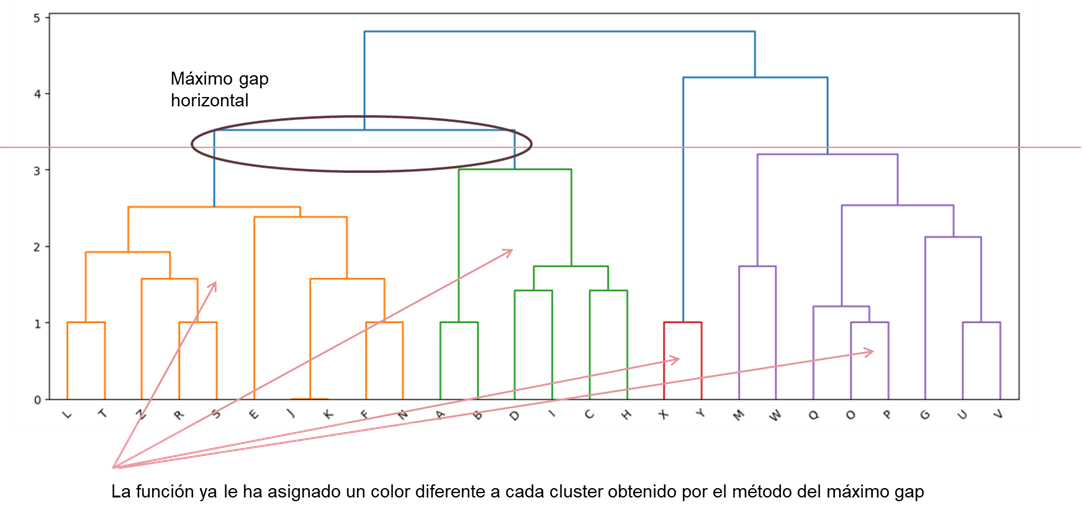

*Solo tenemos que superponer una línea que corte entre 3,20 y 3,52, por ejemplo en 3,3:*

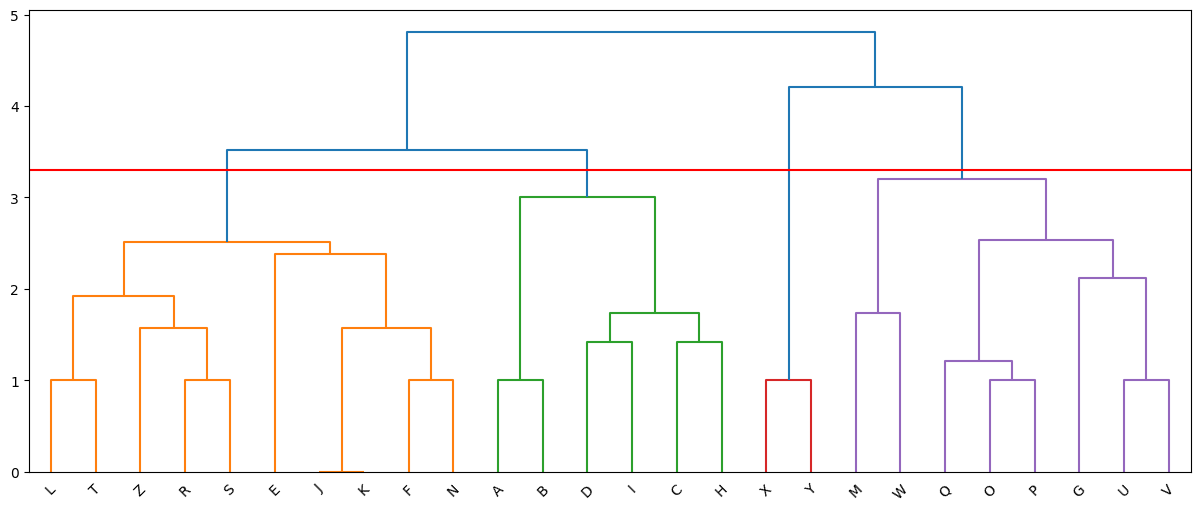

In [15]:
plt.figure(figsize =(15,6))
dend = dendrogram(link_method, labels= labelList)
plt.axhline(y = 3.3, color = 'r', linestyle = '-')

*Nos quedamos, por tanto, con 4 clústeres.*

### Ejercicio 7

Utilizando el código siguiente, emplea el número de clústeres obtenido en el ejercicio anterior (usa 4 si no has logrado obtener un número que te convenza) y muestra cuántas instituciones hay por cluster. ¿Qué te llama la atención?

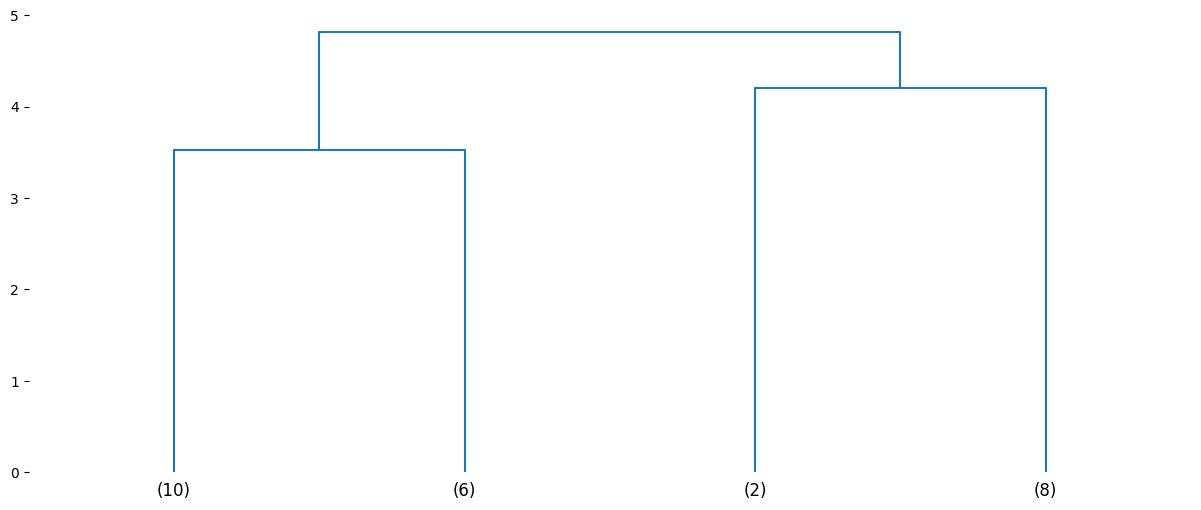

In [16]:
# Miramos cuántos elementos hay en cada cluster
plt.figure(figsize =(15,6))
dend = dendrogram(link_method,
                 truncate_mode='lastp',
                 p = 4,
                 labels = labelList 
                 )
sns.despine(left=True, bottom=True)

*El número de elementos del tercer clúster (2) es bastante menor que en el resto, pero viendo el dendrograma (de los ejercicios anteriores) observa que está bastante distanciado del resto (su línea vertical hasta unirse para formar otro clúster es muy alta, desde el clúster en rojo hasta el siguiente). Son dos instituciones que forman un clúster bastante cohesionado (se unen relativamente pronto) y distante del resto.*

### Ejercicio 8

Previo a analizar las características específicas de cada clúster, analiza el clúster con menor número de elementos, es decir, muestra las características de sus elementos constituyentes.

*Fíjate en que son las instituciones "X" e "Y" (si vas al dendrograma del ejercicio 6 y miras las etiquetas del clúster de dos elementos, verás que son "X" e "Y"). Veamos sus valores:*

In [17]:
train_set[train_set["Engg_College"].isin(["X","Y"])]

,Engg_College,Teaching,Fees,Placements,Internship,Infrastructure
23,X,1,1,1,2,5
24,Y,1,1,1,1,5


*Diríamos que son las "malas": tienen puntuaciones muy bajas en todo menos en infraestructuras (y son también las más baratas, con Fees = 1).*

### Ejercicio 9

Nos hemos adelantado en el ejercicio anterior. Es hora de construir el clustering tal como vimos en la teoría: utiliza el "AgglomerativeClustering" de sklearn para hacer el agrupamiento con el número de clústeres elegido y asigna las etiquetas a cada instancia. (Recuerda que hemos usado el linkage "average", no "ward", que es el más habitual.)

In [18]:
clustering_model = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='average')
clustering_model.fit(train_set[features])
train_set['Cluster'] = clustering_model.labels_

In [19]:
#Frecuencia de elementos en cada cluster

train_set['Cluster'].value_counts()

Cluster
3    10
0     8
1     6
2     2
Name: count, dtype: int64

### Ejercicio 10

Comprueba que las instancias asignadas al clúster con 2 instancias son las entidades "X" e "Y".

In [20]:
train_set[train_set["Engg_College"].isin(["X", "Y"])]

,Engg_College,Teaching,Fees,Placements,Internship,Infrastructure,Cluster
23,X,1,1,1,2,5,2
24,Y,1,1,1,1,5,2


*Las dos están en el clúster 2, que es justo el que tiene 2 instancias según el `value_counts` anterior.*

*Todo OK.*

### Ejercicio 11

Igual que podemos intuir que el cluster "pequeño" es el de las instituciones peor puntuadas, muestra los valores medios de las features para cada clúster y da tu interpretación de qué es cada uno. Emplea un gráfico comparativo.


In [21]:
features_mean_by_cluster = train_set[features + ["Cluster"]].groupby('Cluster').mean()
features_mean_by_cluster['Freq'] = train_set['Cluster'].value_counts().sort_index()

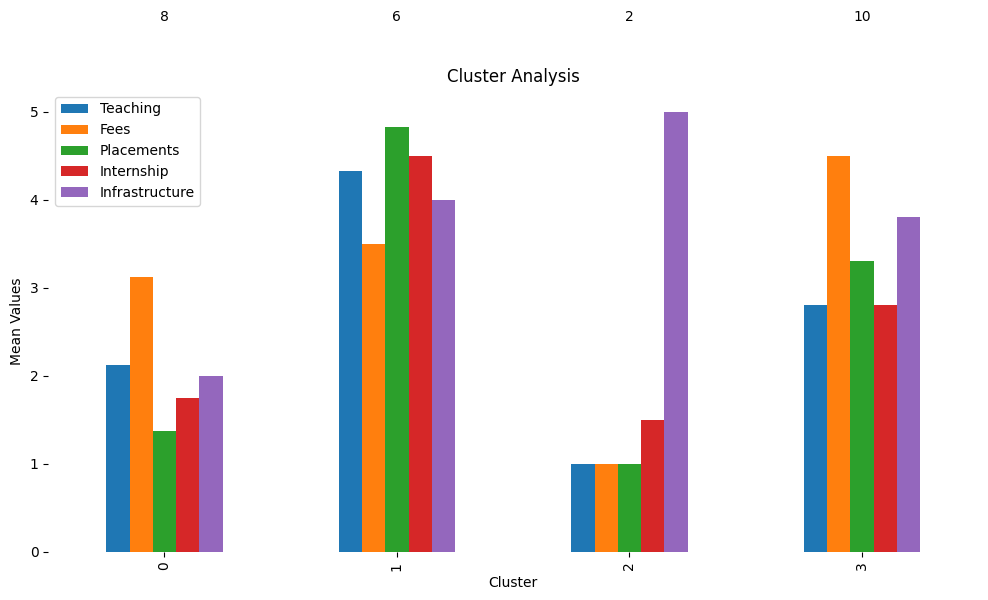

In [22]:
# Perfil de cada cluster
fig, ax = plt.subplots(figsize=(12, 6))
features_mean_by_cluster.iloc[:, :-1].plot(kind='bar', ax=ax)
ax.set_ylabel('Mean Values')
ax.set_title('Cluster Analysis')
for i, v in enumerate(features_mean_by_cluster['Freq']):
    ax.text(i, max(features_mean_by_cluster.iloc[:, :-1].max().max(), 5) + 1, str(v), ha='center', va='bottom')
sns.despine(left=True, bottom=True)
plt.show()

*Podríamos hacer la siguiente interpretación (recuerda que en Fees un valor alto significa más caro):*
* *Clúster 0: instituciones de valoración baja en general (sobre todo en salidas laborales y prácticas) con un coste medio.*
* *Clúster 1: instituciones top en casi todo, con un coste medio-alto.*
* *Clúster 2: instituciones de nivel muy bajo pero las más baratas, que intentan compensarlo con muy buenas infraestructuras.*
* *Clúster 3: instituciones de nivel medio pero las más caras: su calidad no justifica su precio.*

### Ejercicio 12

Para finalizar, ¿qué recomendaciones darías a diferentes clientes en base a los patrones encontrados?

***Recomendaciones***

*1. El clúster 1 es la mejor opción calidad-precio: es el mejor valorado en casi todo y no es el más caro. Sería nuestra recomendación por defecto para quien pueda asumir un coste medio-alto.*
*2. Con un presupuesto muy ajustado solo quedan las instituciones del clúster 2: muy baratas, aunque flojas en todo salvo en infraestructuras.*
*3. No recomendaríamos el clúster 0: cuesta casi lo mismo que el 1 (Fees medio de 3,1 frente a 3,5) con una calidad mucho menor.*
*4. Tampoco el clúster 3: es el más caro y su calidad es media, así que su relación calidad-precio invita claramente a irse al clúster 1.*

*Solo hemos empleado los criterios de nivel y coste; puede ser que, por cercanía o lejanía, fuera necesario cambiar estas recomendaciones.*